<a href="https://colab.research.google.com/github/Prim5787863/Prim-AnalyticsEngineering/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [4]:
display(q("SELECT * FROM trips LIMIT 1"))

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual


In [5]:
display(q("SELECT * FROM bikes LIMIT 1"))

,bike_id,bike_type,purchase_year
0,B001,Standard,2021


In [6]:
display(q("SELECT * FROM stations LIMIT 1"))

,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0


A row of 'trips' table represents an information about an individual trip:
- the bike used
- the start station
- the end station of the trip
- the duration time
- and the user type

A row of 'bikes' table represents an information about an individual bike:
- the bike type
- and the purchase year

A row of 'stations' table represents an information about an individual station:
- station_name
- zone
- and the capacity(?)

In [7]:
from IPython.display import display

trips = tables["trips"]
bikes = tables["bikes"]
stations = tables["stations"]

### Check the data type and null values of each column in the **trips table**

In [8]:
trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trip_id           612 non-null    object 
 1   bike_id           612 non-null    object 
 2   start_station_id  612 non-null    object 
 3   end_station_id    612 non-null    object 
 4   start_time        612 non-null    object 
 5   duration_min      582 non-null    float64
 6   user_type         612 non-null    object 
dtypes: float64(1), object(6)
memory usage: 33.6+ KB


In [9]:
print("--- Value types in each column of TRIPS ---")
for col in trips.columns:
    print(f"\nColumn: '{col}'")
    print(trips[col].apply(type).value_counts())

--- Value types in each column of TRIPS ---

Column: 'trip_id'
trip_id
<class 'str'>    612
Name: count, dtype: int64

Column: 'bike_id'
bike_id
<class 'str'>    612
Name: count, dtype: int64

Column: 'start_station_id'
start_station_id
<class 'str'>    612
Name: count, dtype: int64

Column: 'end_station_id'
end_station_id
<class 'str'>    612
Name: count, dtype: int64

Column: 'start_time'
start_time
<class 'str'>    612
Name: count, dtype: int64

Column: 'duration_min'
duration_min
<class 'float'>    612
Name: count, dtype: int64

Column: 'user_type'
user_type
<class 'str'>    612
Name: count, dtype: int64


In [10]:
trips.isnull().sum()

,0
trip_id,0
bike_id,0
start_station_id,0
end_station_id,0
start_time,0
duration_min,30
user_type,0


In [11]:
print("--- Duplicate values in each column (STATIONS) ---")
for col in trips.columns:
    duplicate_count = trips[col].duplicated().sum()
    print(f"{col}: {duplicate_count} duplicate values")

--- Duplicate values in each column (STATIONS) ---
trip_id: 12 duplicate values
bike_id: 552 duplicate values
start_station_id: 600 duplicate values
end_station_id: 600 duplicate values
start_time: 15 duplicate values
duration_min: 566 duplicate values
user_type: 605 duplicate values


In [12]:
bikes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   bike_id        60 non-null     object
 1   bike_type      60 non-null     object
 2   purchase_year  60 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.5+ KB


In [13]:
print("--- Value types in each column of TRIPS ---")
for col in bikes.columns:
    print(f"\nColumn: '{col}'")
    print(bikes[col].apply(type).value_counts())

--- Value types in each column of TRIPS ---

Column: 'bike_id'
bike_id
<class 'str'>    60
Name: count, dtype: int64

Column: 'bike_type'
bike_type
<class 'str'>    60
Name: count, dtype: int64

Column: 'purchase_year'
purchase_year
<class 'int'>    60
Name: count, dtype: int64


In [14]:
bikes.isnull().sum()

,0
bike_id,0
bike_type,0
purchase_year,0


In [15]:
print("--- Duplicate values in each column (STATIONS) ---")
for col in bikes.columns:
    duplicate_count = bikes[col].duplicated().sum()
    print(f"{col}: {duplicate_count} duplicate values")

--- Duplicate values in each column (STATIONS) ---
bike_id: 0 duplicate values
bike_type: 53 duplicate values
purchase_year: 56 duplicate values


In [16]:
stations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    12 non-null     object 
 1   station_name  12 non-null     object 
 2   zone          12 non-null     object 
 3   capacity      11 non-null     float64
dtypes: float64(1), object(3)
memory usage: 516.0+ bytes


In [17]:
print("--- Value types in each column of TRIPS ---")
for col in stations.columns:
    print(f"\nColumn: '{col}'")
    print(stations[col].apply(type).value_counts())

--- Value types in each column of TRIPS ---

Column: 'station_id'
station_id
<class 'str'>    12
Name: count, dtype: int64

Column: 'station_name'
station_name
<class 'str'>    12
Name: count, dtype: int64

Column: 'zone'
zone
<class 'str'>    12
Name: count, dtype: int64

Column: 'capacity'
capacity
<class 'float'>    12
Name: count, dtype: int64


In [18]:
stations.isnull().sum()

,0
station_id,0
station_name,0
zone,0
capacity,1


In [19]:
print("--- Duplicate values in each column (STATIONS) ---")
for col in stations.columns:
    duplicate_count = stations[col].duplicated().sum()
    print(f"{col}: {duplicate_count} duplicate values")

--- Duplicate values in each column (STATIONS) ---
station_id: 0 duplicate values
station_name: 0 duplicate values
zone: 7 duplicate values
capacity: 1 duplicate values


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

## bike_type

In [20]:
bikes['bike_type'].value_counts()

,count
bike_type,
Standard,36
Electric,9
STANDARD,8
standard,3
Electric,2
electric,1
E-bike,1


In [21]:
test_bikes = bikes

names = {
    'Standard': ['Standard', 'STANDARD', 'standard'],
    'Electric': ['Electric', 'Electric ', 'ELECTRIC', 'electric', 'E-bike']
}

In [22]:
def map_type(value):
    for category, values in names.items():
        if value in values:
            return category
    return 'Unknown'  # Default in case no match is found

test_bikes['new_bike_type'] = test_bikes['bike_type'].apply(map_type)

In [23]:
test_bikes['new_bike_type'].value_counts()

,count
new_bike_type,
Standard,47
Electric,13


## zone

In [24]:
stations['zone'].value_counts()

,count
zone,
Centre,5
North,2
West,2
South,2
East,1


## start_station_id

In [25]:
trips['start_station_id'].value_counts().sort_index(ascending=True)

,count
start_station_id,
S01,82
S02,87
S03,38
S04,57
S05,33
S06,41
S07,38
S08,54
S09,52


## duration_min

In [26]:
# drop missing value average duration
test_trips = trips.dropna(subset=['duration_min'])

print("Missing values after dropping:")
print(test_trips.isnull().sum())

Missing values after dropping:
trip_id             0
bike_id             0
start_station_id    0
end_station_id      0
start_time          0
duration_min        0
user_type           0
dtype: int64


In [27]:
# specified values outside the standard deviation

# Calculate 25th percentile of annual strikes
percentile10 = test_trips['duration_min'].quantile(0.10)

# Calculate 75th percentile of annual strikes
percentile90 = test_trips['duration_min'].quantile(0.90)

# Calculate interquartile range
iqr = percentile90 - percentile10

# Calculate upper and lower thresholds for outliers
upper_limit = percentile90 + 1.5 * iqr
lower_limit = percentile10 - 1.5 * iqr

In [28]:
test_trips[test_trips['duration_min'] < lower_limit]

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type


In [29]:
test_trips[test_trips['duration_min'] > upper_limit].sort_values(by='duration_min', ascending=False)

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
80,T0081,B010,S12,S11,2025-03-04 21:57:00,2880.0,Member
143,T0143,B020,S09,S10,2025-03-08 12:23:00,1440.0,Casual
287,T0284,B046,S08,S03,2025-03-15 20:25:00,1440.0,Member
127,T0127,B025,S08,S09,2025-03-07 09:01:00,90.0,Member
357,T0352,B042,S03,S02,2025-03-19 08:59:00,67.0,Member


## trip_id

In [30]:
# Filter out ALL rows that share a duplicated trip_id (keep=False removes all occurrences)
test_trips[test_trips['trip_id'].duplicated(keep=False)].sort_values(by='trip_id')

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
96,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
97,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
175,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
176,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
185,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
186,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
285,T0283,B014,S07,S04,2025-03-15 19:48:00,5.0,Member
286,T0283,B014,S07,S04,2025-03-15 19:48:00,5.0,Member
326,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member
327,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member


In [31]:
test_trips = test_trips.drop_duplicates(subset=['trip_id'])

test_trips['trip_id'].duplicated().sum()

np.int64(0)

In [32]:
print("--- Duplicate values in each column (STATIONS) ---")
for col in test_trips.columns:
    duplicate_count = test_trips[col].duplicated().sum()
    print(f"{col}: {duplicate_count} duplicate values")

--- Duplicate values in each column (STATIONS) ---
trip_id: 0 duplicate values
bike_id: 510 duplicate values
start_station_id: 558 duplicate values
end_station_id: 558 duplicate values
start_time: 2 duplicate values
duration_min: 525 duplicate values
user_type: 563 duplicate values


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [33]:
new_table = test_trips[['trip_id', 'bike_id', 'start_station_id', 'duration_min']].reset_index(drop=True)
new_table

,trip_id,bike_id,start_station_id,duration_min
0,T0001,B028,S05,21.0
1,T0002,B043,S12,27.0
2,T0003,B045,S11,18.0
3,T0004,B051,S04,34.0
4,T0005,B049,S01,16.0
...,...,...,...,...
565,T0595,B060,S02,12.0
566,T0597,B011,S01,19.0
567,T0598,B046,S06,12.0
568,T0599,B027,S04,21.0


In [34]:
new_table = pd.merge(new_table, test_bikes[['bike_id', 'new_bike_type']], on='bike_id', how='left')
new_table

,trip_id,bike_id,start_station_id,duration_min,new_bike_type
0,T0001,B028,S05,21.0,Standard
1,T0002,B043,S12,27.0,Standard
2,T0003,B045,S11,18.0,Standard
3,T0004,B051,S04,34.0,Electric
4,T0005,B049,S01,16.0,Standard
...,...,...,...,...,...
565,T0595,B060,S02,12.0,Standard
566,T0597,B011,S01,19.0,Electric
567,T0598,B046,S06,12.0,Standard
568,T0599,B027,S04,21.0,Standard


In [35]:
new_table = new_table.rename(columns={'start_station_id': 'station_id'})
new_table

,trip_id,bike_id,station_id,duration_min,new_bike_type
0,T0001,B028,S05,21.0,Standard
1,T0002,B043,S12,27.0,Standard
2,T0003,B045,S11,18.0,Standard
3,T0004,B051,S04,34.0,Electric
4,T0005,B049,S01,16.0,Standard
...,...,...,...,...,...
565,T0595,B060,S02,12.0,Standard
566,T0597,B011,S01,19.0,Electric
567,T0598,B046,S06,12.0,Standard
568,T0599,B027,S04,21.0,Standard


In [36]:
new_table = pd.merge(new_table, stations[['station_id', 'zone']], on='station_id', how='left')
new_table

,trip_id,bike_id,station_id,duration_min,new_bike_type,zone
0,T0001,B028,S05,21.0,Standard,South
1,T0002,B043,S12,27.0,Standard,Centre
2,T0003,B045,S11,18.0,Standard,West
3,T0004,B051,S04,34.0,Electric,West
4,T0005,B049,S01,16.0,Standard,Centre
...,...,...,...,...,...,...
565,T0595,B060,S02,12.0,Standard,Centre
566,T0597,B011,S01,19.0,Electric,Centre
567,T0598,B046,S06,12.0,Standard,Centre
568,T0599,B027,S04,21.0,Standard,West


In [37]:
new_table.sort_values(by='duration_min', ascending=False)

,trip_id,bike_id,station_id,duration_min,new_bike_type,zone
74,T0081,B010,S12,2880.0,Standard,Centre
270,T0284,B046,S08,1440.0,Standard,South
133,T0143,B020,S09,1440.0,Standard,Centre
117,T0127,B025,S08,90.0,Standard,South
334,T0352,B042,S03,67.0,Standard,North
...,...,...,...,...,...,...
298,T0314,B014,S07,6.0,Electric,East
269,T0283,B014,S07,5.0,Electric,East
23,T0026,B033,S08,4.0,Electric,South
347,T0366,B019,S09,4.0,Standard,Centre


In [38]:
check_outliers_1 = new_table[(new_table['new_bike_type'] == 'Standard')]
check_outliers_1.shape

(409, 6)

In [39]:
# Corrected filter and value_counts for new_bike_type == 'Standard' and zone == 'Centre'
check_outliers_2 = new_table[(new_table['zone'] == 'Centre')]
check_outliers_2.shape

(298, 6)

In [40]:
check_outliers_3 = new_table[(new_table['zone'] == 'South')]
check_outliers_3.shape

(84, 6)

In [41]:
# Filter out rows with extreme durations of 2880 and 1440 minutes
new_table = new_table[~new_table['duration_min'].isin([2880.0, 1440.0])].reset_index(drop=True)

In [42]:
new_table.sort_values(by='duration_min', ascending=False)

,trip_id,bike_id,station_id,duration_min,new_bike_type,zone
116,T0127,B025,S08,90.0,Standard,South
331,T0352,B042,S03,67.0,Standard,North
303,T0323,B023,S08,52.0,Standard,South
482,T0512,B045,S07,51.0,Standard,East
34,T0038,B016,S12,50.0,Standard,Centre
...,...,...,...,...,...,...
274,T0292,B039,S12,6.0,Standard,Centre
267,T0283,B014,S07,5.0,Electric,East
23,T0026,B033,S08,4.0,Electric,South
307,T0327,B055,S01,4.0,Standard,Centre


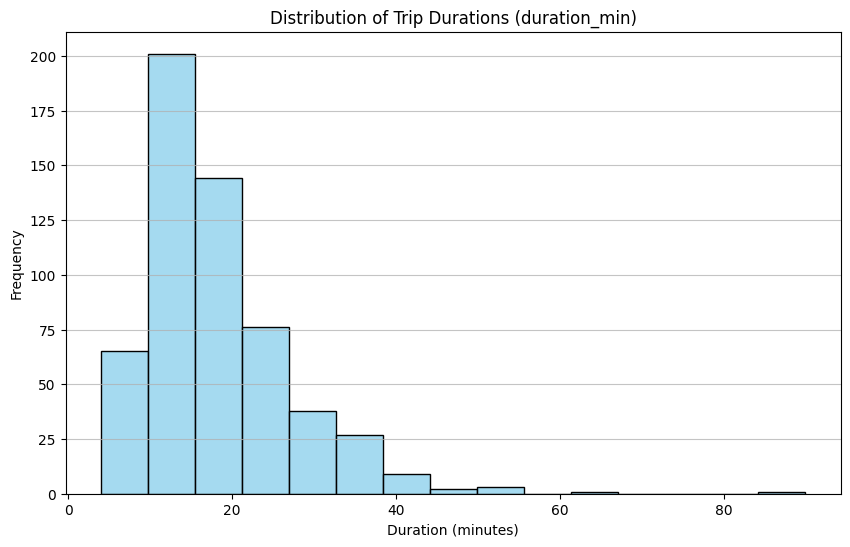

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot histogram of duration_min
plt.figure(figsize=(10, 6))
sns.histplot(new_table['duration_min'], bins=15, color='skyblue')
plt.title('Distribution of Trip Durations (duration_min)')
plt.xlabel('Duration (minutes)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [44]:
summary_table = new_table.groupby(['new_bike_type', 'zone'])['trip_id'].aggregate(["count"])
summary_table

count
new_bike_type zone         
Electric      Centre     81
              East       11
              North      23
              South      24
              West       22
Standard      Centre    215
              East       20
              North      39
              South      59
              West       73

In [45]:
new_table.groupby(['new_bike_type', 'zone']).aggregate(
    number_of_trips = ("trip_id", "count"),
    average_duration = ("duration_min", "mean")
).reset_index()

,new_bike_type,zone,number_of_trips,average_duration
0,Electric,Centre,81,14.506173
1,Electric,East,11,15.727273
2,Electric,North,23,15.956522
3,Electric,South,24,13.416667
4,Electric,West,22,15.681818
5,Standard,Centre,215,18.925581
6,Standard,East,20,19.500000
7,Standard,North,39,20.358974
8,Standard,South,59,19.474576
9,Standard,West,73,19.821918


In [46]:
new_table.groupby('new_bike_type')['duration_min'].aggregate(["mean"])

,mean
new_bike_type,
Electric,14.795031
Standard,19.332512


In [47]:
new_table.groupby('zone')['duration_min'].aggregate(["mean"])

,mean
zone,
Centre,17.716216
East,18.161290
North,18.725806
South,17.722892
West,18.863158


## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

## 6. What I could not verify

*What remains unchecked? What would you do next?*